# Owner: SONG Haoyu, M4 final evaluation; shared M4 with FOTSING TANKOU DAN KATEL
# One final check on the later years

Run this after `04_ensembles.ipynb` and `05_catboost_interpretation.ipynb`. Both training workflows must be complete. We carry forward the logistic baseline, the best full-training OOF AutoML model, the best ensemble and CatBoost. The models and F2 thresholds are already fixed.

This notebook creates a frozen plan before making test predictions. Later runs reuse those predictions. If the data, model settings or thresholds change, it stops instead of silently turning the test set into another tuning set.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, joblib, pandas as pd
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.models.m4_common import CACHE
from src.config import RESULTS_DIR
from src.evaluation.final_evaluation import final_predictions, final_report
ensemble = joblib.load(CACHE / 'ensembles.joblib')
cat = joblib.load(CACHE / 'catboost.joblib')
print('Training-only choices:', ensemble['best_automl'], ensemble['best_ensemble'], 'CatBoost')
training = pd.concat([pd.read_csv(RESULTS_DIR / 'ensembles_train.csv'), pd.read_csv(RESULTS_DIR / 'catboost_train.csv')])
display(training.sort_values('pr_auc', ascending=False).round(4))

Training-only choices: Random forest Boosting CatBoost


,model,scored_on,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,CatBoost,out-of-fold (5 grouped folds),0.6469,0.8902,0.4294,0.8715,0.7227,0.4237,0.3659
5,Boosting,out-of-fold (5 grouped folds),0.6302,0.8842,0.4162,0.8715,0.7151,0.4394,0.3775
7,Stacking,out-of-fold (5 grouped folds),0.6250,0.8812,0.4085,0.8728,0.7111,0.1135,0.3852
6,Soft voting,out-of-fold (5 grouped folds),0.6249,0.8812,0.4086,0.8726,0.7111,0.2999,0.3850
3,Random forest,out-of-fold (5 grouped folds),0.6140,0.8775,0.3996,0.8777,0.7082,0.1582,0.3960
4,Bagging,out-of-fold (5 grouped folds),0.6036,0.8718,0.3882,0.8777,0.7010,0.4127,0.4076
1,Logistic regression,out-of-fold (5 grouped folds),0.5889,0.8722,0.3959,0.8750,0.7045,0.4147,0.3985
0,Logistic baseline,out-of-fold (5 grouped folds),0.5888,0.8722,0.3954,0.8757,0.7045,0.4130,0.3993
2,Decision tree,out-of-fold (5 grouped folds),0.5834,0.8616,0.3887,0.8584,0.6913,0.4416,0.3982


## 1. Fit once, predict once

We fit each final model on all of 2019–2023, then predict 2024–2025. We do not optimize thresholds or choose a new model from these results. The test labels are used only for the reports below.

In [2]:
y_test, test_meta, predictions, thresholds = final_predictions(ensemble, cat)
display(pd.DataFrame({'model': list(thresholds), 'frozen_threshold': list(thresholds.values())}))
print(f'Test set: {len(y_test):,} people from {test_meta.Num_Acc.nunique():,} accidents')
print((RESULTS_DIR / 'm4_final_plan.json').read_text())

Logistic baseline: fitting on all training years, then predicting the test years once


Random forest: fitting on all training years, then predicting the test years once


Boosting: fitting on all training years, then predicting the test years once


CatBoost: fitting on all training years, then predicting the test years once


,model,frozen_threshold
0,Logistic baseline,0.413023
1,Random forest,0.158198
2,Boosting,0.439383
3,CatBoost,0.423745


Test set: 251,563 people from 109,495 accidents
{
  "frozen_at_utc": "2026-11-28T12:13:57.925283+00:00",
  "plan": {
    "run_id": "734efc841d8b51f8",
    "chosen": [
      "Logistic baseline",
      "Random forest",
      "Boosting",
      "CatBoost"
    ],
    "thresholds": {
      "Logistic baseline": 0.413023327963105,
      "Random forest": 0.15819807078106937,
      "Boosting": 0.4393830067026446,
      "CatBoost": 0.42374461403378005
    },
    "model_signature": "d572a8715e9288cbe15123ad4b8b5130",
    "stack_signature": null,
    "test_index_signature": "6823c527c84aca5e8004ff3b39679471",
    "test_years": [
      2024,
      2025
    ],
    "train_people": 619552,
    "test_people": 251563,
    "environment": {
      "python": "3.12.14",
      "numpy": "2.0.2",
      "pandas": "2.3.3",
      "scikit-learn": "1.9.1",
      "catboost": "1.2.10",
      "shap": "0.54.1"
    }
  }
}


## 2. Scores and uncertainty

The main score is average precision, which we call PR-AUC throughout the project. Precision, recall and F2 use the unchanged training thresholds. We sample complete accidents 1,000 times to get percentile 95% confidence intervals. These intervals describe the fixed fitted models on a resampled test population; they do not include retraining uncertainty.

For each comparison with the logistic baseline, both models use the same resampled accidents. A positive difference favours the named model. These are exploratory, unadjusted pairwise intervals, so we avoid making a blanket significance claim from several comparisons.

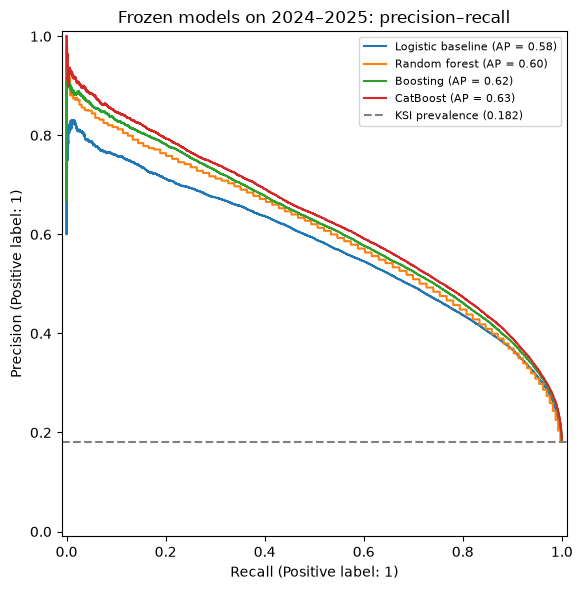

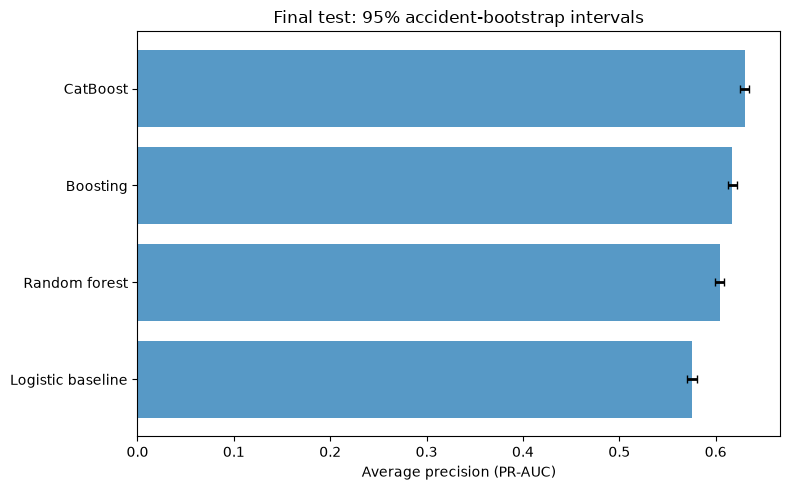

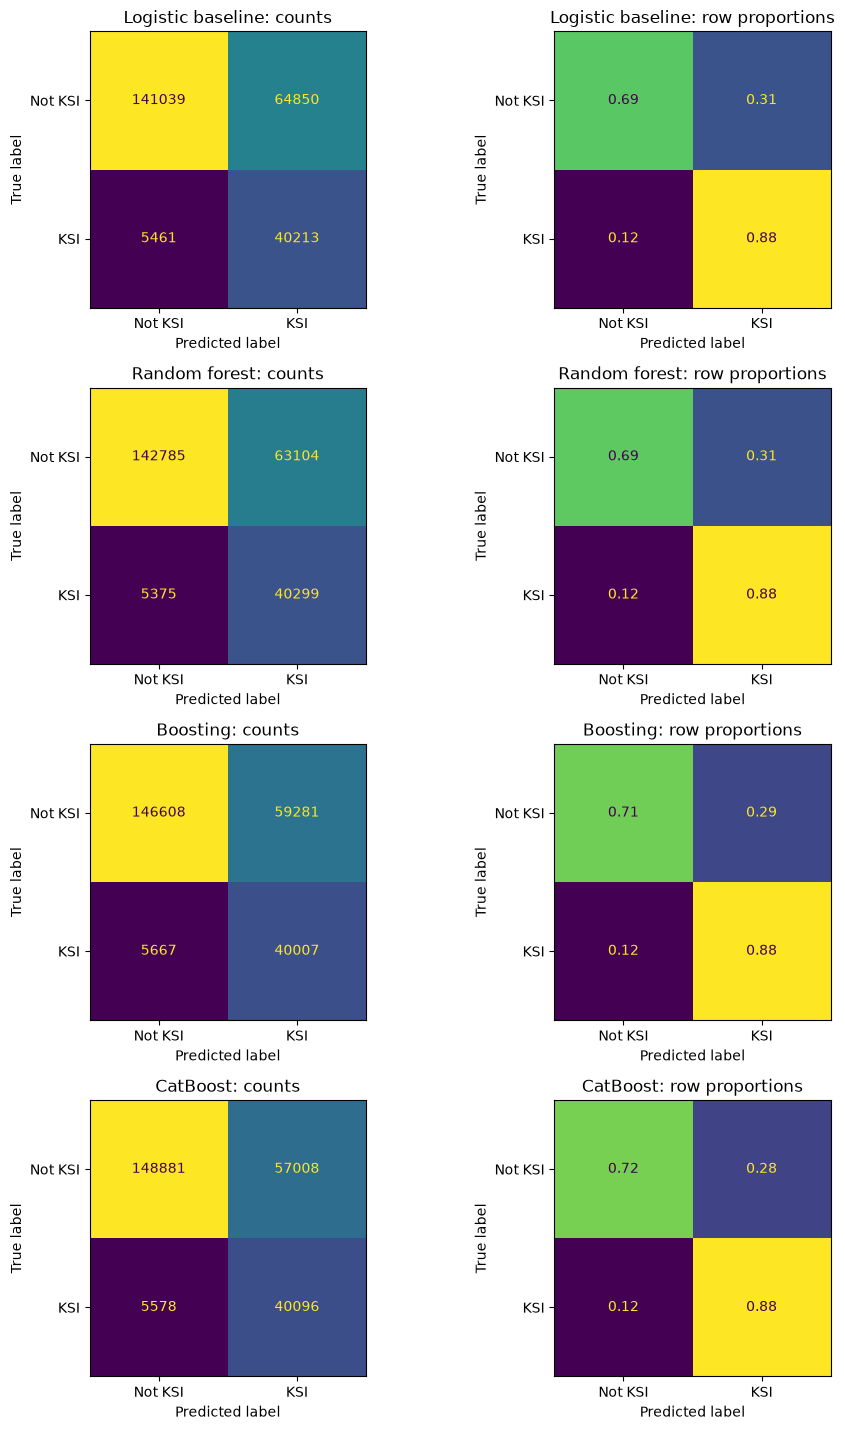

,model,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,Logistic baseline,0.5752,0.8659,0.3828,0.8804,0.6987,0.4130,0.4176
1,Random forest,0.6043,0.8732,0.3897,0.8823,0.7043,0.1582,0.4110
2,Boosting,0.6174,0.8784,0.4029,0.8759,0.7094,0.4394,0.3947
3,CatBoost,0.6303,0.8831,0.4129,0.8779,0.7165,0.4237,0.3860


,model,metric,estimate,low,high
0,Logistic baseline,pr_auc,0.5752,0.5700,0.5805
7,Random forest,pr_auc,0.6043,0.5994,0.6092
14,Boosting,pr_auc,0.6174,0.6124,0.6224
21,CatBoost,pr_auc,0.6303,0.6255,0.6350


,model,reference,metric,estimate,low,high
0,Random forest,Logistic baseline,pr_auc,0.0291,0.0256,0.0324
7,Boosting,Logistic baseline,pr_auc,0.0421,0.0396,0.0447
14,CatBoost,Logistic baseline,pr_auc,0.0551,0.0521,0.0580


Random forest minus baseline: +0.0291, 95% CI [+0.0256, +0.0324] (above zero).
Boosting minus baseline: +0.0421, 95% CI [+0.0396, +0.0447] (above zero).
CatBoost minus baseline: +0.0551, 95% CI [+0.0521, +0.0580] (above zero).


In [3]:
summary, ci, paired, yearly = final_report(y_test, test_meta, predictions, thresholds, n_boot=1000)
display(summary.round(4))
display(ci.query("metric == 'pr_auc'").round(4))
display(paired.query("metric == 'pr_auc'").round(4))
for row in paired.query("metric == 'pr_auc'").itertuples():
    evidence = 'above zero' if row.low > 0 else ('below zero' if row.high < 0 else 'includes zero')
    print(f'{row.model} minus baseline: {row.estimate:+.4f}, 95% CI [{row.low:+.4f}, {row.high:+.4f}] ({evidence}).')

## 3. Does performance look different by year?

We report 2024 and 2025 separately using the same thresholds. Differences can reflect changes in the population, data recording or the relationship between features and severity. Two yearly scores alone do not identify which explanation is responsible. We also show the KSI prevalence, because precision–recall results depend on class prevalence.

In [4]:
display(yearly.round(4))
by_year = yearly.pivot(index='model', columns='year', values='pr_auc')
by_year['2025 minus 2024'] = by_year[2025] - by_year[2024]
display(by_year.round(4))

,year,model,n_people,ksi_rate,pr_auc,roc_auc,precision,recall,f2,threshold,predicted_ksi_share
0,2024,Logistic baseline,125187,0.1802,0.5782,0.8679,0.3852,0.8797,0.7000,0.4130,0.4115
1,2024,Random forest,125187,0.1802,0.6081,0.8756,0.3917,0.8827,0.7057,0.1582,0.4061
2,2024,Boosting,125187,0.1802,0.6211,0.8804,0.4052,0.8766,0.7112,0.4394,0.3898
3,2024,CatBoost,125187,0.1802,0.6356,0.8857,0.4154,0.8781,0.7182,0.4237,0.3809
4,2025,Logistic baseline,126376,0.1829,0.5727,0.8640,0.3804,0.8812,0.6975,0.4130,0.4237
5,2025,Random forest,126376,0.1829,0.6008,0.8708,0.3879,0.8819,0.7029,0.1582,0.4159
6,2025,Boosting,126376,0.1829,0.6139,0.8764,0.4007,0.8753,0.7077,0.4394,0.3995
7,2025,CatBoost,126376,0.1829,0.6255,0.8806,0.4105,0.8776,0.7149,0.4237,0.3911


year,2024,2025,2025 minus 2024
model,,,
Boosting,0.6211,0.6139,-0.0072
CatBoost,0.6356,0.6255,-0.0101
Logistic baseline,0.5782,0.5727,-0.0055
Random forest,0.6081,0.6008,-0.0073


In [5]:
from IPython.display import Markdown
ap = ci.query("metric == 'pr_auc'").set_index('model')
lines = []
for name, row in ap.iterrows():
    lines.append(f"- **{name}**: PR-AUC {row.estimate:.4f}, with a 95% accident-bootstrap interval of [{row.low:.4f}, {row.high:.4f}].")
shifts = by_year['2025 minus 2024']
lines.append(f"\nAcross the four frozen models, the change from 2024 to 2025 ranges from {shifts.min():+.4f} to {shifts.max():+.4f} PR-AUC. We read that alongside the prevalence in the yearly table; this is a descriptive drift check, not a diagnosis of its cause.")
display(Markdown("### Reading the final results\n\n" + "\n".join(lines)))

### Reading the final results

- **Logistic baseline**: PR-AUC 0.5752, with a 95% accident-bootstrap interval of [0.5700, 0.5805].
- **Random forest**: PR-AUC 0.6043, with a 95% accident-bootstrap interval of [0.5994, 0.6092].
- **Boosting**: PR-AUC 0.6174, with a 95% accident-bootstrap interval of [0.6124, 0.6224].
- **CatBoost**: PR-AUC 0.6303, with a 95% accident-bootstrap interval of [0.6255, 0.6350].

Across the four frozen models, the change from 2024 to 2025 ranges from -0.0101 to -0.0055 PR-AUC. We read that alongside the prevalence in the yearly table; this is a descriptive drift check, not a diagnosis of its cause.

## What we would tell a road-safety team

Use the subgroup errors and the risk-situation table alongside the headline score. A model can rank people well overall and still miss a particular group. The scores concern severity among people in recorded injury accidents, not the chance of having an accident in the first place.

The explanations show associations in the fitted models. They do not establish that changing one feature would prevent an injury. Before any operational use, we would need an agreed decision process, a closer calibration check and validation on newer data. The results above are the project’s frozen final comparison; they are not a new round of tuning.